In [1]:
%matplotlib inline

In [2]:
import sys
sys.path.append("..")

In [3]:
import pathlib

In [13]:
import s1isp
import s1isp.decoder
from s1isp.decoder import EUdfDecodingMode

## Data decoding

In [11]:
print($PATH)


SyntaxError: invalid syntax (2134581518.py, line 1)

In [14]:
# Please make sure to download the product in the specified path
filename = pathlib.Path(
    "/home/joe/Work/Projects/RSAR/Datasets/xView3/Data/Misc/S1B_S3_RAW_0SDV_20200615T162409_20200615T162435_022046_029D76_F3E6/RAW/product/S1B_S3_RAW__0SDV_20200615T162409_20200615T162435_022046_029D76_F3E6.SAFE/"
    "s1b-s3-raw-s-vv-20200615t162409-20200615t162435-022046-029d76.dat"
)

In [15]:
print(filename)

/home/joe/Work/Projects/RSAR/Datasets/xView3/Data/Misc/S1B_S3_RAW_0SDV_20200615T162409_20200615T162435_022046_029D76_F3E6/RAW/product/S1B_S3_RAW__0SDV_20200615T162409_20200615T162435_022046_029D76_F3E6.SAFE/s1b-s3-raw-s-vv-20200615t162409-20200615t162435-022046-029d76.dat


In [16]:
records, offsets, subcom_data_records = s1isp.decoder.decode_stream(
    filename,
    maxcount=1000,  # comment out this line to decode all the ISPs in the file
    udf_decoding_mode=EUdfDecodingMode.DECODE,
)

decoded: 1001 packets [00:00, 1083.95 packets/s]


### Records can be easily converted int Pandas DataFrames

In [17]:
import pandas as pd

headers_data = s1isp.decoder.decoded_stream_to_dict(records)
df = pd.DataFrame(headers_data)

df

,packet_version_number,packet_type,secondary_header_flag,pid,pcat,sequence_flags,packet_sequence_count,packet_data_length,coarse_time,fine_time,...,azimuth_beam_address,sas_test,cal_type,calibration_beam_address,cal_mode,tx_pulse_number,signal_type,swap,swath_number,number_of_quads
0,0,0,True,65,12,3,0,27097,1276273467,43887,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_preamble,2,noise,False,2,10779
1,0,0,True,65,12,3,1,27097,1276273467,43921,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_preamble,2,noise,False,2,10779
2,0,0,True,65,12,3,2,27097,1276273467,43955,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_preamble,2,noise,False,2,10779
3,0,0,True,65,12,3,3,27097,1276273467,43989,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_preamble,2,noise,False,2,10779
4,0,0,True,65,12,3,4,27097,1276273467,44023,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_preamble,2,noise,False,2,10779
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
996,0,0,True,65,12,3,996,15745,1276273468,16346,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_interleaved,2,echo,False,2,10779
997,0,0,True,65,12,3,997,15769,1276273468,16380,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_interleaved,2,echo,False,2,10779
998,0,0,True,65,12,3,998,15837,1276273468,16414,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_interleaved,2,echo,False,2,10779
999,0,0,True,65,12,3,999,15797,1276273468,16448,...,0,sat_test_mode_active,epdn_cal,0,pcc2_ical_interleaved,2,echo,False,2,10779


#### Display primary and secondary header data

In [18]:
# noise
# idx = 0
# labal = "noise"

# tx-cal
idx = 8
label = "Tx cal" 

# echo
# idx = 500
# label = "echo"

In [19]:

df.signal_type[idx]

'tx_cal'

In [20]:
df.iloc[idx]

packet_version_number                           0
packet_type                                     0
secondary_header_flag                        True
pid                                            65
pcat                                           12
sequence_flags                                  3
packet_sequence_count                           8
packet_data_length                           7653
coarse_time                            1276273467
fine_time                                   44500
sync_marker                             892270675
data_take_id                             87747936
ecc_num                                s3_no_ical
test_mode                                 default
rx_channel_id                                 rxv
instrument_configuration_id                     1
data_word_index                                 9
space_packet_count                              8
pri_count                                    3917
error_flag                                  False


### Display data

In [21]:
tx_cal = records[idx].udf

In [22]:
tx_cal

array([ 1.+1.j,  1.+0.j,  0.+0.j, ..., -1.+1.j, -2.+0.j,  0.+0.j],
      dtype=complex64)

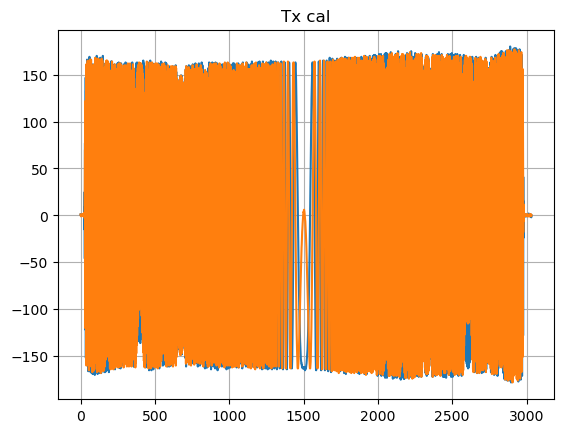

In [23]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots()
ax.plot(tx_cal.real, label="real")
ax.plot(tx_cal.imag, label="imag")
ax.grid()
ax.set_title(label);